In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import geobr
from pathlib import Path
import sys
sys.path.append(str(Path.cwd().parent.parent))
from src.soja_clima.merge import carregar_base_final  # base única: base_final_modelagem.csv
from src.soja_clima.geo import mapa_estacoes_cd_micro  # mapa estação->microrregião em memória

PROCESSED_DIR = Path("../../data/processed")
df = carregar_base_final(PROCESSED_DIR / "base_final_modelagem.csv")

# Padroniza chaves
df['CD_MICRO'] = df['CD_MICRO'].astype(float).astype(int).astype(str)

# Cria classificação climática baseada no ONI
def classificar_oni(oni):
    if pd.isna(oni): return 'Sem dado'
    if oni >= 0.5: return 'El Niño'
    if oni <= -0.5: return 'La Niña'
    return 'Neutro'

df['fenomeno'] = df['oni_medio'].apply(classificar_oni)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)
print("Dados preparados. Distribuição de anos por fenômeno:")
print(df.groupby('ano')['fenomeno'].first().value_counts())

Dados preparados. Distribuição de anos por fenômeno:
fenomeno
Sem dado    9
Neutro      7
La Niña     5
El Niño     5
Name: count, dtype: int64


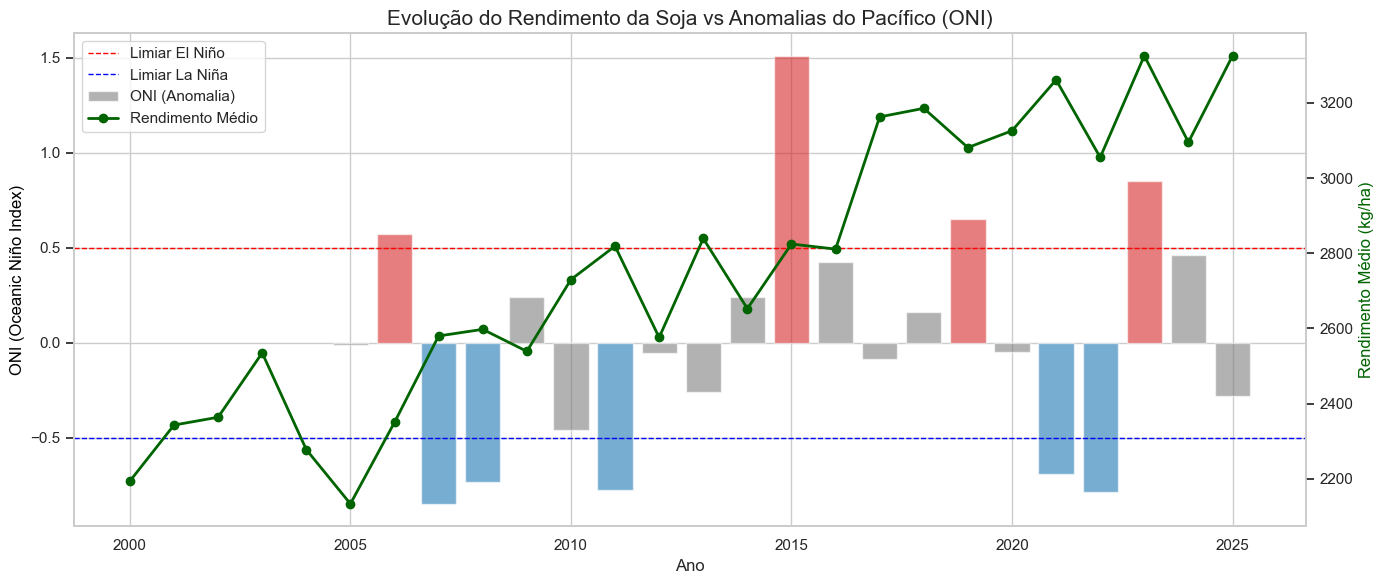

In [2]:
# Agrega para o Brasil por ano
serie_anual = df.groupby('ano').agg(
    rendimento_medio=('rendimento_recalculado', 'mean'),
    oni=('oni_medio', 'mean'),
    soei=('soi_medio', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Eixo 1: Barras coloridas pelo ONI
cores = ['#d62728' if x >= 0.5 else '#1f77b4' if x <= -0.5 else '#7f7f7f' for x in serie_anual['oni']]
ax1.bar(serie_anual['ano'], serie_anual['oni'], color=cores, alpha=0.6, label='ONI (Anomalia)')
ax1.axhline(0.5, color='red', linestyle='--', linewidth=1, label='Limiar El Niño')
ax1.axhline(-0.5, color='blue', linestyle='--', linewidth=1, label='Limiar La Niña')
ax1.set_ylabel('ONI (Oceanic Niño Index)', color='black')
ax1.set_xlabel('Ano')

# Eixo 2: Linha do rendimento
ax2 = ax1.twinx()
ax2.plot(serie_anual['ano'], serie_anual['rendimento_medio'], color='darkgreen', marker='o', linewidth=2, label='Rendimento Médio')
ax2.set_ylabel('Rendimento Médio (kg/ha)', color='darkgreen')
ax2.grid(False)

# Legenda
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Evolução do Rendimento da Soja vs Anomalias do Pacífico (ONI)', fontsize=15)
plt.tight_layout()
plt.show()

/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_73281/3231596423.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


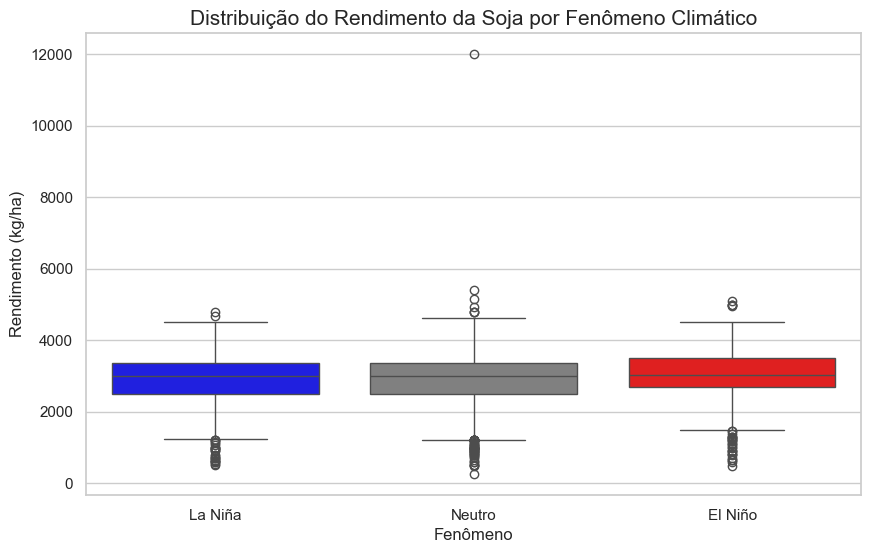

           count     mean     std     min     25%      50%      75%      max
fenomeno                                                                    
El Niño   1026.0  3032.57  685.66  479.83  2700.0  3039.17  3500.00   5100.0
La Niña   1115.0  2906.81  687.41  500.00  2500.0  3000.00  3360.00   4800.0
Neutro    2638.0  2932.07  709.64  254.04  2500.0  3000.00  3360.00  12000.0
Sem dado  2214.0  2460.98  686.20  105.56  2100.0  2500.00  2990.43   5400.0


In [3]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df, 
    x='fenomeno', 
    y='rendimento_recalculado', 
    order=['La Niña', 'Neutro', 'El Niño'],
    palette={'La Niña': 'blue', 'Neutro': 'gray', 'El Niño': 'red'}
)
plt.title('Distribuição do Rendimento da Soja por Fenômeno Climático', fontsize=15)
plt.ylabel('Rendimento (kg/ha)')
plt.xlabel('Fenômeno')
plt.show()

print(df.groupby('fenomeno')['rendimento_recalculado'].describe().round(2))

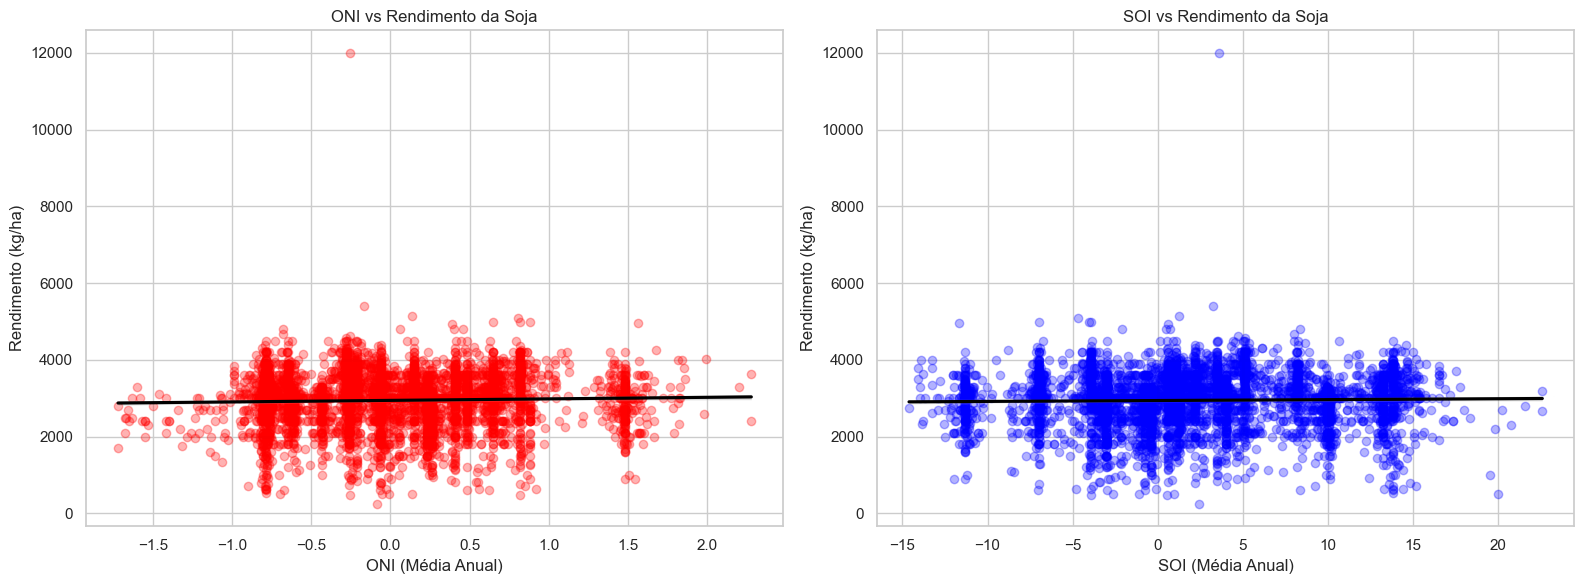

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ONI vs Rendimento
sns.regplot(data=df, x='oni_medio', y='rendimento_recalculado', ax=axes[0], 
            scatter_kws={'alpha':0.3, 'color': 'red'}, line_kws={'color': 'black'})
axes[0].set_title('ONI vs Rendimento da Soja')
axes[0].set_xlabel('ONI (Média Anual)')
axes[0].set_ylabel('Rendimento (kg/ha)')

# SOI vs Rendimento
sns.regplot(data=df, x='soi_medio', y='rendimento_recalculado', ax=axes[1], 
            scatter_kws={'alpha':0.3, 'color': 'blue'}, line_kws={'color': 'black'})
axes[1].set_title('SOI vs Rendimento da Soja')
axes[1].set_xlabel('SOI (Média Anual)')
axes[1].set_ylabel('Rendimento (kg/ha)')

plt.tight_layout()
plt.show()

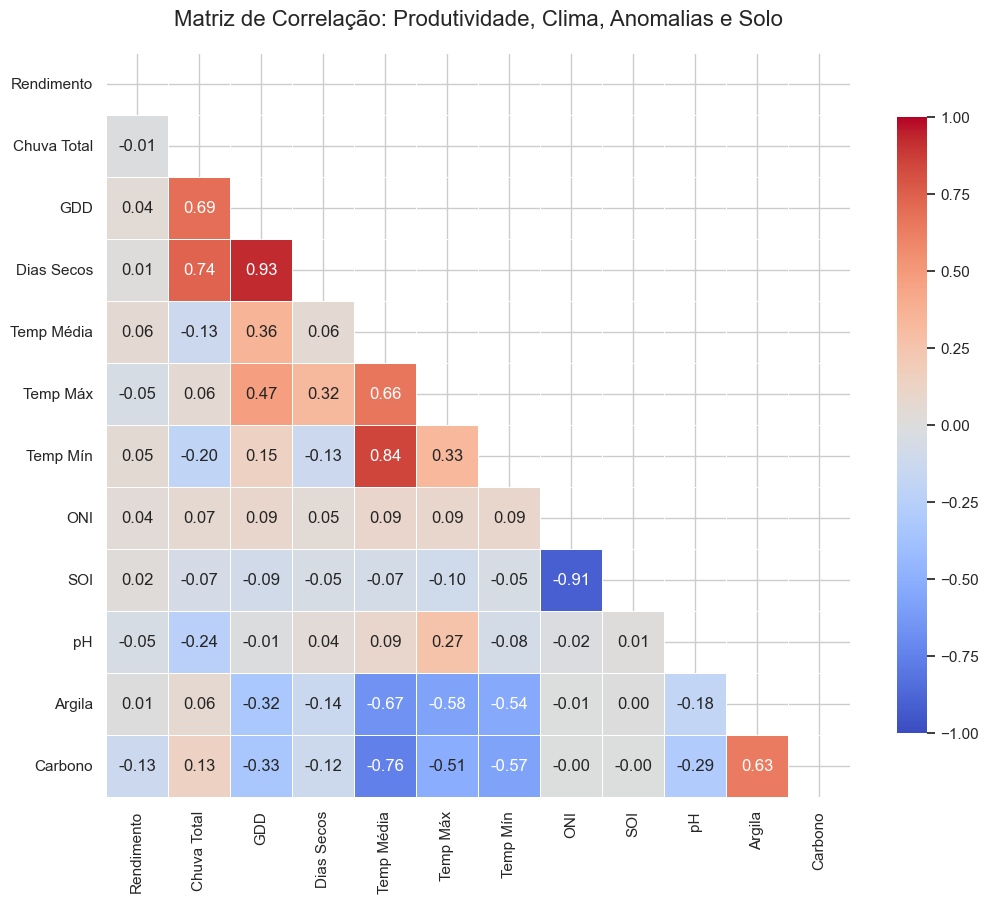

In [5]:
cols_alvo = [
    'rendimento_recalculado', 'precipitacao_total', 'gdd_total', 'dias_secos_total',
    'temp_media_anual', 'temp_max_anual', 'temp_min_anual',
    'oni_medio', 'soi_medio', 
    'phh2o_0-5cm_mean', 'clay_0-5cm_mean', 'soc_0-5cm_mean'
]

# Renomeia para o gráfico ficar legível
labels = {
    'rendimento_recalculado': 'Rendimento', 'precipitacao_total': 'Chuva Total',
    'gdd_total': 'GDD', 'dias_secos_total': 'Dias Secos',
    'temp_media_anual': 'Temp Média', 'temp_max_anual': 'Temp Máx', 'temp_min_anual': 'Temp Mín',
    'oni_medio': 'ONI', 'soi_medio': 'SOI',
    'phh2o_0-5cm_mean': 'pH', 'clay_0-5cm_mean': 'Argila', 'soc_0-5cm_mean': 'Carbono'
}

df_corr = df[cols_alvo].rename(columns=labels).corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(df_corr, dtype=bool))
sns.heatmap(df_corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", 
            vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Matriz de Correlação: Produtividade, Clima, Anomalias e Solo", fontsize=16, pad=20)
plt.show()

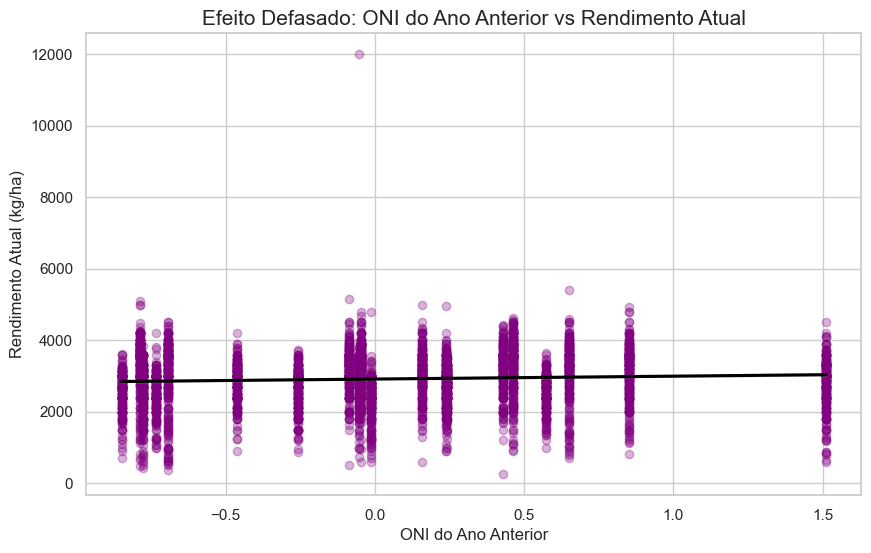

In [6]:
# Cria a coluna de ONI do ano anterior
serie_oni = df.groupby('ano')['oni_medio'].mean().reset_index()
serie_oni['oni_ano_anterior'] = serie_oni['oni_medio'].shift(1)

df_lag = df.merge(serie_oni[['ano', 'oni_ano_anterior']], on='ano', how='left')

plt.figure(figsize=(10, 6))
sns.regplot(data=df_lag, x='oni_ano_anterior', y='rendimento_recalculado', 
            scatter_kws={'alpha':0.3, 'color': 'purple'}, line_kws={'color': 'black'})
plt.title('Efeito Defasado: ONI do Ano Anterior vs Rendimento Atual', fontsize=15)
plt.xlabel('ONI do Ano Anterior')
plt.ylabel('Rendimento Atual (kg/ha)')
plt.show()

/usr/local/Caskroom/miniconda/base/envs/pcd2_env/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/Caskroom/miniconda/base/envs/pcd2_env/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/usr/local/Caskroom/miniconda/base/envs/pcd2_env/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/Caskroom/miniconda/base/envs/pcd2_env/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2894: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/Caskroom/miniconda/base/envs/pcd2_env/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2894: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/fold

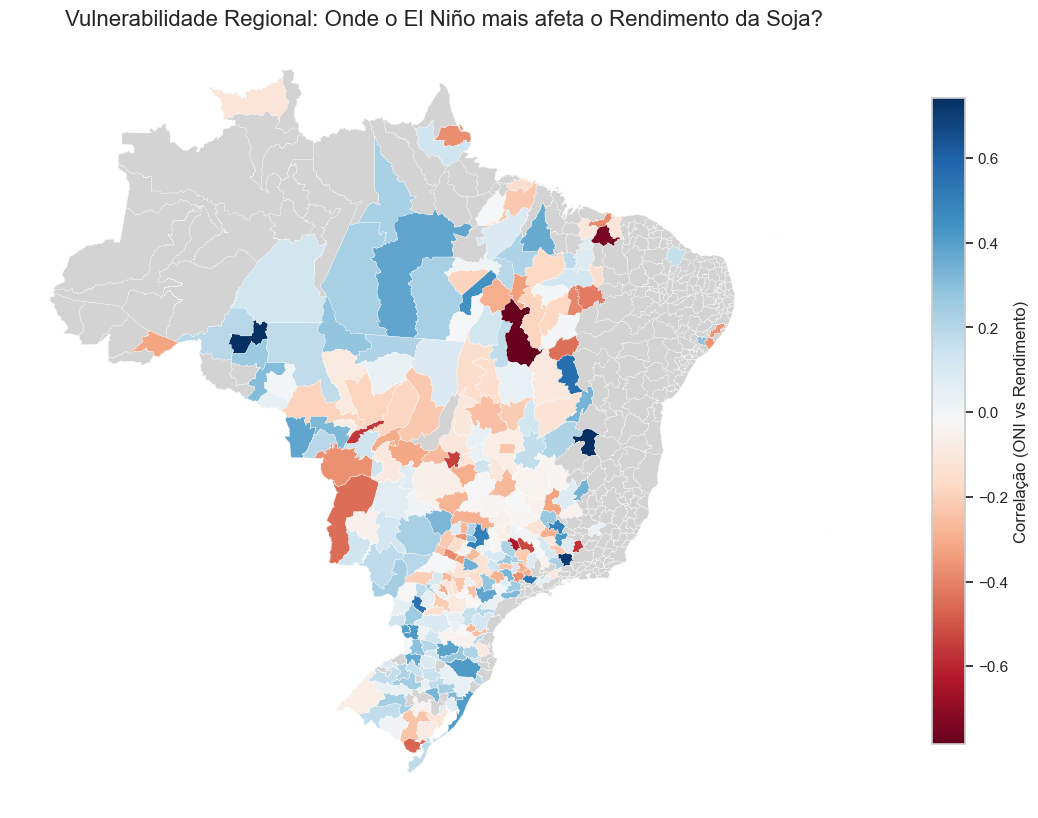

Legenda do mapa:
  Azul escuro = El Niño forte diminui muito o rendimento (Vulnerável)
  Vermelho = El Niño forte aumenta o rendimento
  Cinza = Microrregiões com menos de 10 anos de dados


In [7]:
# Calcula a correlação local (por microrregião) entre ONI e Rendimento
def calcular_corr_local(grupo):
    # Só calcula se tiver pelo menos 10 anos de dados
    if len(grupo) >= 10:
        return grupo['oni_medio'].corr(grupo['rendimento_recalculado'])
    return np.nan

corr_local = df.groupby('CD_MICRO').apply(calcular_corr_local).reset_index()
corr_local.columns = ['CD_MICRO', 'correlacao_oni_rendimento']

# Junta com o mapa
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_plot = gdf_micro.merge(corr_local, left_on='code_micro', right_on='CD_MICRO', how='left')

fig, ax = plt.subplots(figsize=(14, 14))
gdf_plot.plot(
    column='correlacao_oni_rendimento', 
    cmap='RdBu', # Vermelho = correlação positiva, Azul = negativa
    legend=True, 
    legend_kwds={'label': 'Correlação (ONI vs Rendimento)', 'shrink': 0.6},
    missing_kwds={'color': 'lightgrey', 'label': 'Sem dados suficientes'},
    edgecolor='white', 
    linewidth=0.2, 
    ax=ax
)
ax.set_title('Vulnerabilidade Regional: Onde o El Niño mais afeta o Rendimento da Soja?', fontsize=16)
ax.axis('off')
plt.show()

print("Legenda do mapa:")
print("  Azul escuro = El Niño forte diminui muito o rendimento (Vulnerável)")
print("  Vermelho = El Niño forte aumenta o rendimento")
print("  Cinza = Microrregiões com menos de 10 anos de dados")